#Data Visualization

##Pandas, Matplotlib, and Seaborn

###Assignment Tasks:

###1) Loading the Taxis Dataset using the following code:
####import seaborn as sns
#### Load the 'taxis' dataset
####df = sns.load_dataset("taxis")

In [1]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
# Load the 'taxis' dataset
df = sns.load_dataset("taxis")
print(df.head())
print(df.info())
print(df.shape)

               pickup             dropoff  passengers  distance  fare   tip  \
0 2019-03-23 20:21:09 2019-03-23 20:27:24           1      1.60   7.0  2.15   
1 2019-03-04 16:11:55 2019-03-04 16:19:00           1      0.79   5.0  0.00   
2 2019-03-27 17:53:01 2019-03-27 18:00:25           1      1.37   7.5  2.36   
3 2019-03-10 01:23:59 2019-03-10 01:49:51           1      7.70  27.0  6.15   
4 2019-03-30 13:27:42 2019-03-30 13:37:14           3      2.16   9.0  1.10   

   tolls  total   color      payment            pickup_zone  \
0    0.0  12.95  yellow  credit card        Lenox Hill West   
1    0.0   9.30  yellow         cash  Upper West Side South   
2    0.0  14.16  yellow  credit card          Alphabet City   
3    0.0  36.95  yellow  credit card              Hudson Sq   
4    0.0  13.40  yellow  credit card           Midtown East   

            dropoff_zone pickup_borough dropoff_borough  
0    UN/Turtle Bay South      Manhattan       Manhattan  
1  Upper West Side South      

###2) Handling Missing Values

In [2]:
#● Check for missing values in the dataset and identify columns with missing data.
df


,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6428,2019-03-31 09:51:53,2019-03-31 09:55:27,1,0.75,4.5,1.06,0.0,6.36,green,credit card,East Harlem North,Central Harlem North,Manhattan,Manhattan
6429,2019-03-31 17:38:00,2019-03-31 18:34:23,1,18.74,58.0,0.00,0.0,58.80,green,credit card,Jamaica,East Concourse/Concourse Village,Queens,Bronx
6430,2019-03-23 22:55:18,2019-03-23 23:14:25,1,4.14,16.0,0.00,0.0,17.30,green,cash,Crown Heights North,Bushwick North,Brooklyn,Brooklyn
6431,2019-03-04 10:09:25,2019-03-04 10:14:29,1,1.12,6.0,0.00,0.0,6.80,green,credit card,East New York,East Flatbush/Remsen Village,Brooklyn,Brooklyn


In [3]:
# Check missing values in each column
print(df.isnull().sum())

# Display columns containing missing values
print(df.isnull().sum()[df.isnull().sum() > 0])

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64


####● Impute missing values using appropriate strategies based on the column type (e.g.,
using the mean, median, or mode for numerical columns and the mode for categorical
columns).

In [12]:
# Convert pickup to datetime format
df["pickup"] = pd.to_datetime(df["pickup"], errors="coerce")

# Remove rows missing critical values
df = df.dropna(subset=["pickup", "fare"])

# Fill missing numerical values with the median
num_cols = df.select_dtypes(include="number").columns

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

# Fill missing categorical values with the mode
cat_cols = df.select_dtypes(
    include=["object", "category", "string"]
).columns

for col in cat_cols:
    if df[col].isnull().any():
      mode_value = df[col].mode()


# Check missing values after cleaning
print(df.isnull().sum())

print("Dataset cleaned successfully!")

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64
Dataset cleaned successfully!


##3) Visualizations using Matplotlib/Pandas Plot:

###★ Line Chart
Plot a line chart to visualize the fare over time, using the pickup timestamp as the x-axis and
fare as the y-axis. Ensure the pickup column is converted to a datetime format before plotting.

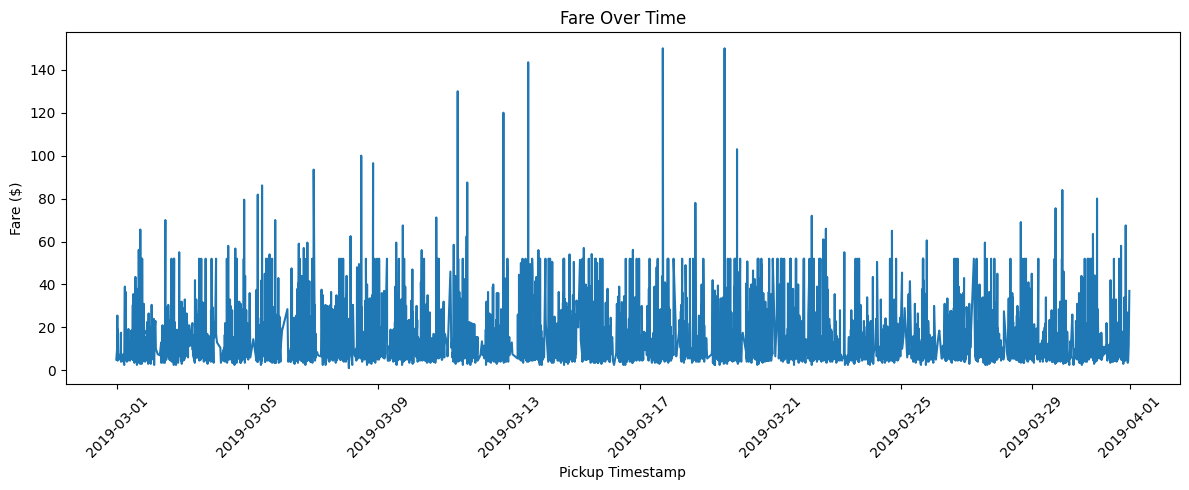

In [13]:
# Sort data by pickup timestamp
line_df = df.sort_values("pickup")

# Create line chart
plt.figure(figsize=(12, 5))
plt.plot(line_df["pickup"], line_df["fare"])

plt.title("Fare Over Time")
plt.xlabel("Pickup Timestamp")
plt.ylabel("Fare ($)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

###★ Bar Chart
Create a bar chart to show the total fare for each pickup_borough. Group the data by
pickup_borough and sum the fare for each group.

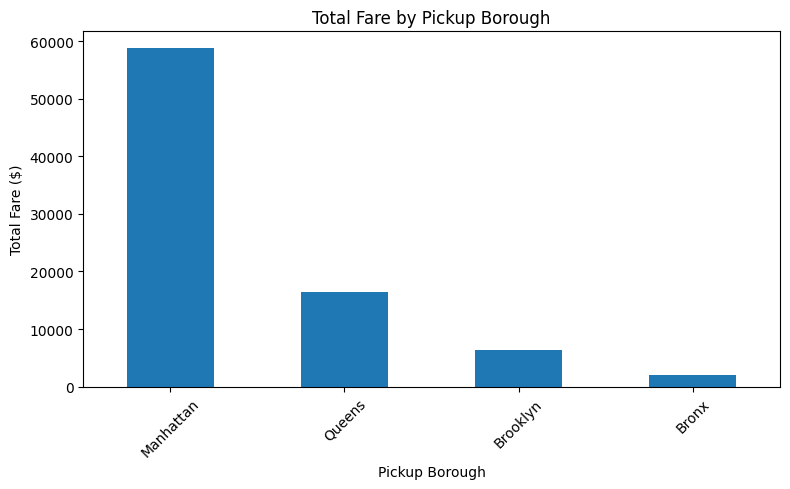

In [14]:
# Calculate total fare for each borough
borough_fare = df.groupby(
    "pickup_borough", observed=True
)["fare"].sum().sort_values(ascending=False)

# Plot bar chart
borough_fare.plot(kind="bar", figsize=(8, 5))

plt.title("Total Fare by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Total Fare ($)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

###★ Pie Chart
Plot a pie chart showing the distribution of trips based on the payment method (credit card,
cash, etc.). Each slice should represent the count of trips for a specific payment method.

In [ ]:
# Count trips by payment method
payment_counts = df["payment"].value_counts()

# Plot pie chart
plt.figure(figsize=(7, 7))
plt.pie(
    payment_counts,
    labels=payment_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Distribution of Trips by Payment Method")
plt.show()

###★ Histogram
Create a histogram to visualize the distribution of distance. Customize the number of bins for
better granularity and ensure the plot is easy to interpret.

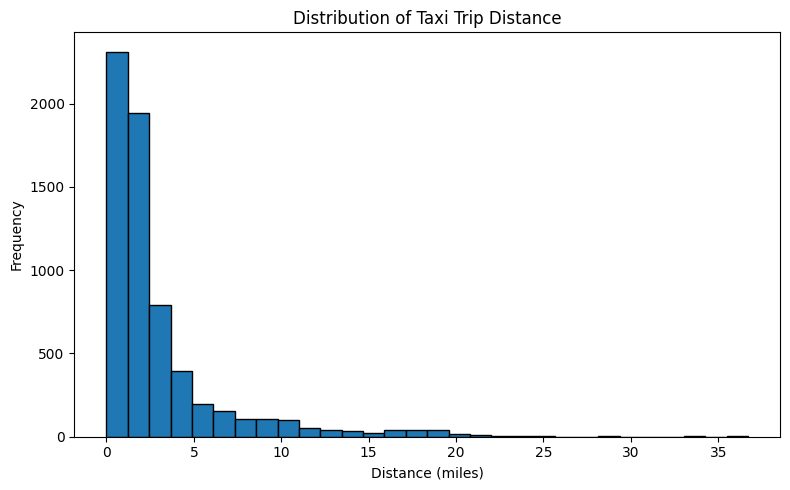

In [16]:
#Histogram
plt.figure(figsize=(8, 5))

plt.hist(df["distance"], bins=30, edgecolor="black")

plt.title("Distribution of Taxi Trip Distance")
plt.xlabel("Distance (miles)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

###★ Box Plot
Plot a box plot to visualize the distribution of tip amounts for each pickup_borough. Use
pickup_borough as the categorical axis and tip as the numeric axis.

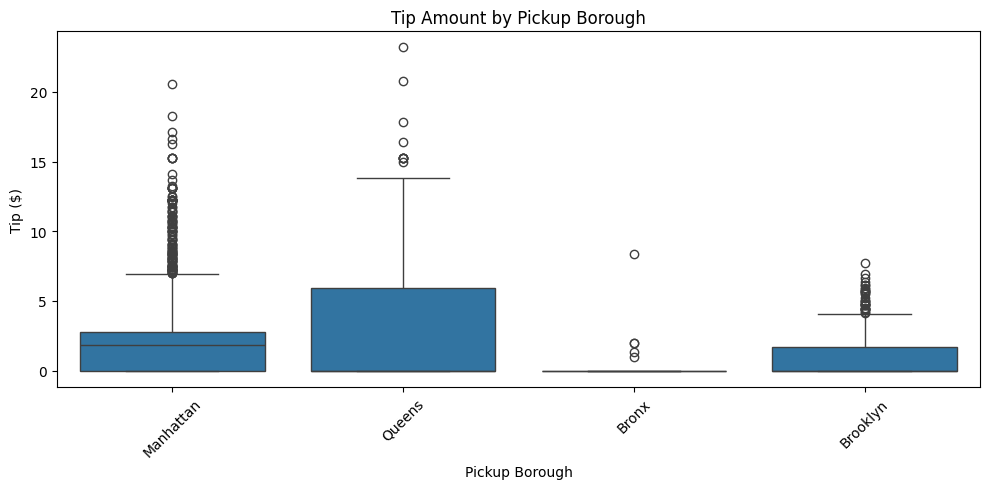

In [17]:
#Box Plot
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="pickup_borough",
    y="tip"
)

plt.title("Tip Amount by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Tip ($)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

##Visualizations using Seaborn:


###★ Count Plot
Create a count plot to visualize the number of trips in each pickup_borough. The x-axis should
represent the boroughs, and the y-axis should show the count of trips.

/tmp/ipykernel_2565/753690700.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


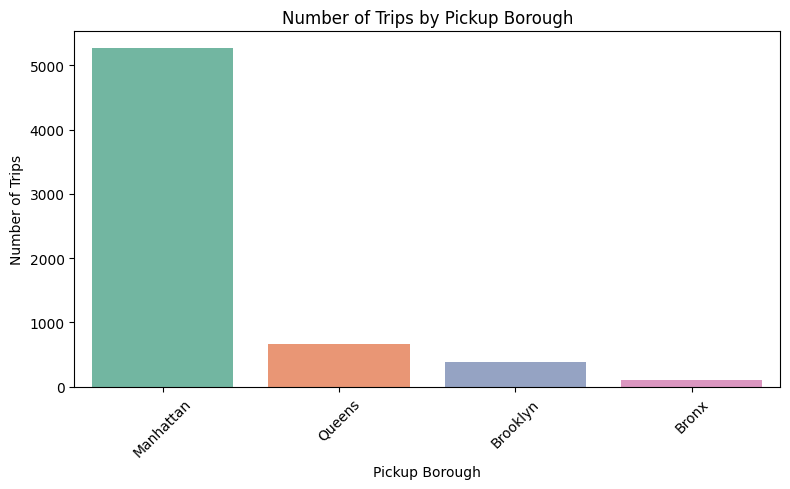

In [22]:
#Count Plot
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="pickup_borough",palette="Set2",
    order=df["pickup_borough"].value_counts().index
)

plt.title("Number of Trips by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Number of Trips")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

##★ Scatter Plot
Plot a scatter plot to show the relationship between distance and fare. Use distance on the
x-axis and fare on the y-axis to visualize any correlation. Color the points based on the
pickup_borough to differentiate the trips by their respective boroughs.

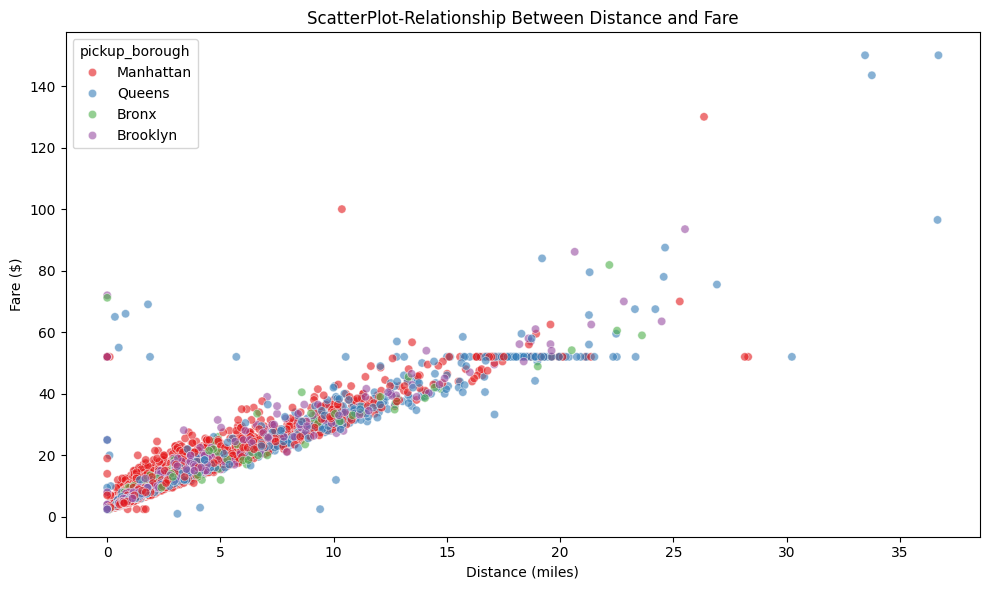

In [23]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="distance",
    y="fare",
    palette='Set1',
    hue="pickup_borough",
    alpha=0.6
)

plt.title("ScatterPlot-Relationship Between Distance and Fare")
plt.xlabel("Distance (miles)")
plt.ylabel("Fare ($)")
plt.tight_layout()
plt.show()

###★ Heatmap
Plot a heatmap to visualize the correlation between numerical variables such as distance, fare,
tip, tolls, and total. Use a correlation matrix to highlight the relationships.

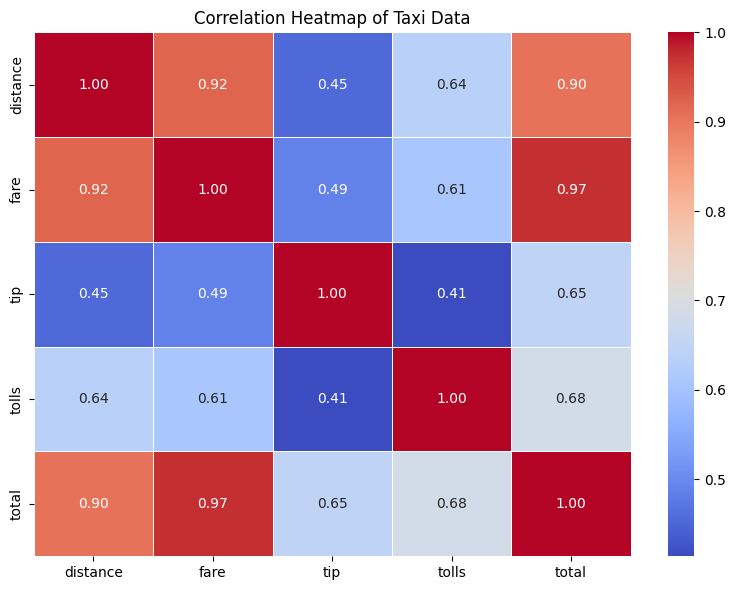

In [24]:
# Select numerical columns
numeric_cols = ["distance", "fare", "tip", "tolls", "total"]

# Calculate correlation matrix
correlation_matrix = df[numeric_cols].corr()

# Plot heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Taxi Data")
plt.tight_layout()
plt.show()

###★ Pair Plot
Create a pair plot to visualize the pairwise relationships between distance, fare, tip, and total.
Color the data points according to the pickup_zone column. to compare how different zones
affect these variables.

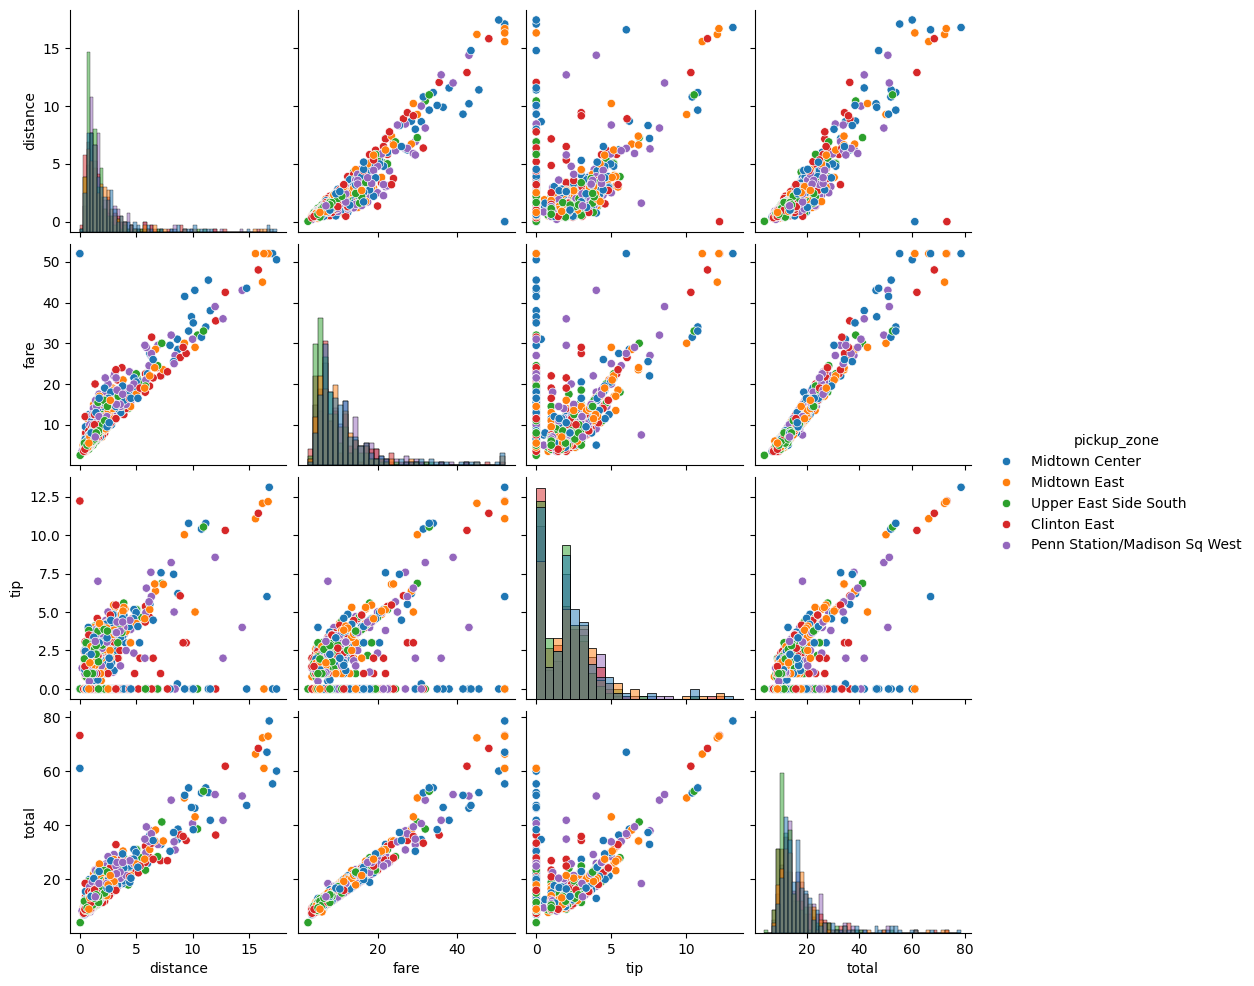

In [25]:
pair_df = df[
    ["distance", "fare", "tip", "total", "pickup_zone"]
].dropna()

# Select the five most frequent pickup zones
top_zones = pair_df["pickup_zone"].value_counts().head(5).index

pair_df = pair_df[
    pair_df["pickup_zone"].isin(top_zones)
]

# Sample data for faster plotting
pair_df = pair_df.sample(
    n=min(1000, len(pair_df)),
    random_state=42
)

# Create pair plot
sns.pairplot(
    pair_df,
    vars=["distance", "fare", "tip", "total"],
    hue="pickup_zone",
    diag_kind="hist"
)
plt.show()

###★ Violin Plot
Plot a violin plot to show the distribution of fare for each payment method. Use the payment
method as the categorical axis and fare as the numeric axis to visualize its distribution.

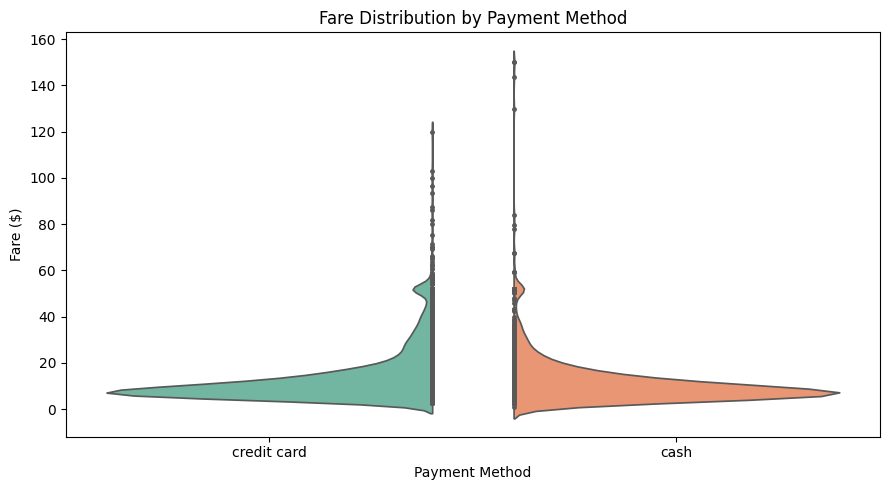

In [31]:
plt.figure(figsize=(9, 5))

sns.violinplot(
    data=df.dropna(subset=["payment"]),
    x="payment",
    y="fare",
    hue="payment",

    split=1,                # split by hue -- True
    inner="point",     # box, quartile, point, stick
    palette="Set2"
)

plt.title("Fare Distribution by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Fare ($)")
plt.tight_layout()
plt.show()